# 03 · Scorecard : WoE / IV + régression logistique

La **scorecard** est le modèle historique des banques : simple, lisible et auditable par un régulateur.
Elle se construit en 4 étapes :

1. **Découper** chaque variable en classes (*bins*).
2. Remplacer chaque valeur par le **WoE** de sa classe.
3. **Sélectionner** les variables utiles grâce à l'**IV**.
4. Ajuster une **régression logistique** sur les WoE.

Le modèle est entraîné par `python -m credit_risk_scoring.scorecard` (environ 1 minute) ; ce notebook le recharge et l'explique.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_curve

from credit_risk_scoring.config import FIGURES
from credit_risk_scoring.modeling import evaluate, load_features, split
from credit_risk_scoring.scorecard import MODEL_PATH

sns.set_theme(style="whitegrid")
pd.set_option("display.max_rows", 100)

df = load_features()
X_train, X_test, y_train, y_test = split(df)
sc = joblib.load(MODEL_PATH)
print(f"Train : {len(X_train):,} · Test : {len(X_test):,} · Variables du modèle : {len(sc.variables)}")

Train : 246,008 · Test : 61,503 · Variables du modèle : 18


## 1. Le découpage en classes et le WoE

Prenons `EXT_SOURCE_3` (score externe). L'algorithme d'**optbinning** cherche les seuils qui séparent le mieux
les bons et les mauvais payeurs, en imposant que le taux de défaut évolue **régulièrement** d'une classe à l'autre.

Pour chaque classe, on calcule le **WoE (Weight of Evidence)** :

$$\text{WoE} = \ln\left(\frac{\%\ \text{des bons payeurs dans la classe}}{\%\ \text{des mauvais payeurs dans la classe}}\right)$$

- **WoE > 0** : la classe contient proportionnellement plus de bons payeurs → **moins risquée** que la moyenne
- **WoE < 0** : plus de mauvais payeurs → **plus risquée**
- **WoE = 0** : risque moyen

In [2]:
table = sc.binning_table("EXT_SOURCE_3")
table[["Bin", "Count", "Count (%)", "Event rate", "WoE", "IV"]]

,Bin,Count,Count (%),Event rate,WoE,IV
0,"(-inf, 0.18)",12843,0.052206,0.220743,-1.171139,0.115351
1,"[0.18, 0.32)",23969,0.097432,0.140014,-0.61731,0.048048
2,"[0.32, 0.41)",23943,0.097326,0.095351,-0.182505,0.003500
3,"[0.41, 0.46)",13375,0.054368,0.079028,0.023145,0.000029
4,"[0.46, 0.50)",13777,0.056002,0.070262,0.150189,0.001186
5,"[0.50, 0.57)",23547,0.095716,0.057332,0.367371,0.011086
6,"[0.57, 0.61)",15501,0.063010,0.049029,0.532588,0.014335
7,"[0.61, 0.65)",13099,0.053246,0.046645,0.584945,0.014305
8,"[0.65, 0.70)",21579,0.087717,0.041800,0.699681,0.032195
9,"[0.70, 0.78)",23442,0.095290,0.033743,0.922179,0.055636


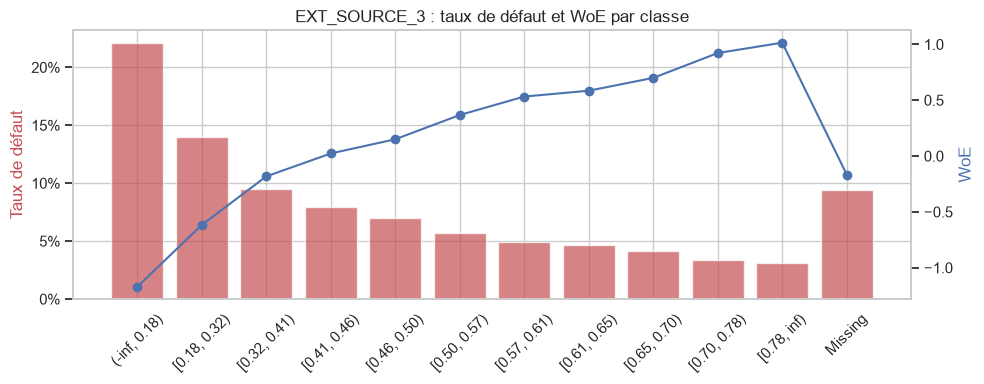

In [3]:
t = table.iloc[:-1]                      # sans la ligne « Totals »
t = t[t["Count"] > 0]
fig, ax1 = plt.subplots(figsize=(10, 4))
ax1.bar(t["Bin"].astype(str), t["Event rate"], color="#C44E52", alpha=0.7)
ax1.set_ylabel("Taux de défaut", color="#C44E52")
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.tick_params(axis="x", rotation=45)
ax2 = ax1.twinx()
ax2.plot(t["Bin"].astype(str), t["WoE"].astype(float), color="#4C72B0", marker="o")
ax2.set_ylabel("WoE", color="#4C72B0"); ax2.grid(False)
ax1.set_title("EXT_SOURCE_3 : taux de défaut et WoE par classe")
plt.tight_layout(); plt.savefig(FIGURES / "03_woe_ext_source_3.png", dpi=120); plt.show()

**Lecture :** dans la classe la plus basse (score < 0,18), 22 % de défauts ; dans la plus haute, 3 %.
Le WoE monte quand le risque baisse. Les valeurs **manquantes** forment leur propre classe, avec leur propre WoE :
c'est ainsi qu'on garde l'information « non renseigné » repérée pendant l'exploration.

**Pourquoi transformer en WoE ?**
- toutes les variables passent sur **la même échelle**, y compris les catégorielles (métier, type d'organisation…) ;
- les **valeurs extrêmes** ne posent plus de problème (elles tombent dans la dernière classe) ;
- les relations **non linéaires** deviennent exploitables par une régression logistique, qui est un modèle linéaire.

## 2. L'IV : quelle variable est utile ?

L'**IV (Information Value)** additionne la contribution de chaque classe :

$$\text{IV} = \sum_{\text{classes}} (\%\ \text{bons} - \%\ \text{mauvais}) \times \text{WoE}$$

Échelle habituelle en scoring :

| IV | Pouvoir prédictif |
|---|---|
| < 0,02 | inutile |
| 0,02 – 0,1 | faible |
| 0,1 – 0,3 | moyen |
| > 0,3 | fort |

Variables testées : 170 · IV >= 0,02 : 81


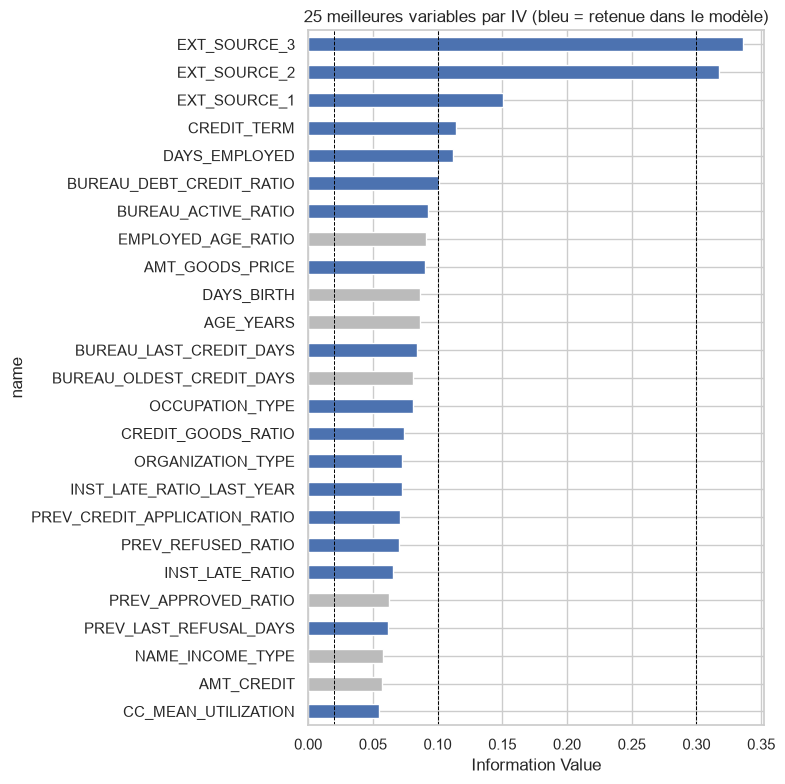

In [4]:
iv = sc.iv
print(f"Variables testées : {len(iv)} · IV >= 0,02 : {(iv >= 0.02).sum()}")
top = iv.head(25)[::-1]
colors = ["#4C72B0" if v in sc.variables else "#BBBBBB" for v in top.index]
ax = top.plot.barh(figsize=(8, 8), color=colors)
for x in (0.02, 0.1, 0.3):
    ax.axvline(x, color="black", ls="--", lw=0.7)
ax.set_title("25 meilleures variables par IV (bleu = retenue dans le modèle)")
ax.set_xlabel("Information Value")
plt.tight_layout(); plt.savefig(FIGURES / "03_iv.png", dpi=120); plt.show()

Les scores externes `EXT_SOURCE_2` et `EXT_SOURCE_3` sont les seuls « forts ». Viennent ensuite des variables
**créées en SQL** : `CREDIT_TERM`, `BUREAU_DEBT_CREDIT_RATIO`, `BUREAU_ACTIVE_RATIO`… Le feature engineering paie.

Certaines variables grises ont un bon IV mais ne sont **pas retenues** : elles sont trop corrélées à une variable déjà choisie
(par exemple `AGE_YEARS` et `DAYS_BIRTH` contiennent exactement la même information).

## 3. Sélection des variables

1. **IV ≥ 0,02** : 81 variables.
2. **Corrélation < 0,6** entre WoE : parmi deux variables redondantes, on garde celle qui a le plus d'IV.
3. **20 variables maximum** : au-delà, la scorecard devient difficile à lire pour un analyste crédit.
4. **Signe cohérent** : avec le WoE, un coefficient doit être **négatif** (WoE élevé = bon payeur = risque plus faible).
   Un coefficient positif voudrait dire « plus la classe est saine, plus le risque augmente » : c'est absurde, on retire la variable.

In [5]:
print("Retirées pour signe incohérent :", sc.dropped_wrong_sign)
woe_train = sc.binning.transform(X_train, metric="woe")
from sklearn.linear_model import LinearRegression, LogisticRegression

# Corrélation de l'âge avec les variables du modèle
print(woe_train[sc.variables].corrwith(woe_train["DAYS_BIRTH"]).sort_values(ascending=False).head(4).round(2).to_string())

# Part de l'information sur l'âge déjà contenue dans les 18 autres variables
r2 = LinearRegression().fit(woe_train[sc.variables], woe_train["DAYS_BIRTH"]).score(woe_train[sc.variables], woe_train["DAYS_BIRTH"])
print()
print(f"R² de l'âge expliqué par les variables du modèle : {r2:.2f}")

# Coefficient de l'âge seul, puis avec les autres variables
seul = LogisticRegression(max_iter=1000).fit(woe_train[["DAYS_BIRTH"]], y_train).coef_[0][0]
avec = LogisticRegression(max_iter=1000).fit(woe_train[sc.variables + ["DAYS_BIRTH"]], y_train).coef_[0][-1]
print(f"Coefficient de l'âge seul : {seul:.2f} · avec les autres variables : {avec:.2f}")

Retirées pour signe incohérent : ['DAYS_BIRTH', 'BUREAU_OLDEST_CREDIT_DAYS']


ORGANIZATION_TYPE    0.45
DAYS_EMPLOYED        0.28
EXT_SOURCE_1         0.25
EXT_SOURCE_3         0.18



R² de l'âge expliqué par les variables du modèle : 0.32


Coefficient de l'âge seul : -1.00 · avec les autres variables : 0.11


`DAYS_BIRTH` (l'âge) est pourtant très prédictif **seul** : son coefficient est nettement négatif, dans le bon sens.
Mais une partie de son information est **déjà présente** dans d'autres variables, surtout `ORGANIZATION_TYPE`
(la catégorie `XNA` regroupe les retraités), `DAYS_EMPLOYED` (dont l'anomalie signale aussi les retraités) et `EXT_SOURCE_1`.
Une fois ces variables dans le modèle, l'âge n'apporte presque plus rien de nouveau : son coefficient devient faible et **change de signe**.

C'est la **multicolinéarité** : quand plusieurs variables se recoupent, les coefficients deviennent instables et difficiles à interpréter.
L'information sur l'âge n'est pas perdue, elle passe par les autres variables.

## 4. Le modèle final

In [6]:
coefs = sc.coefficients().sort_values("IV", ascending=False)
coefs.style.format({"coefficient": "{:.3f}", "IV": "{:.3f}"}).bar(subset=["IV"], color="#9DB4D4")

,coefficient,IV
EXT_SOURCE_3,-0.631,0.336
EXT_SOURCE_2,-0.776,0.317
EXT_SOURCE_1,-0.514,0.151
CREDIT_TERM,-0.369,0.114
DAYS_EMPLOYED,-0.372,0.112
BUREAU_DEBT_CREDIT_RATIO,-0.293,0.101
BUREAU_ACTIVE_RATIO,-0.105,0.092
AMT_GOODS_PRICE,-0.291,0.091
BUREAU_LAST_CREDIT_DAYS,-0.194,0.084
OCCUPATION_TYPE,-0.481,0.081


Chaque coefficient indique le **poids** de la variable : plus il est grand en valeur absolue, plus la variable compte
dans la décision. Ces coefficients serviront plus tard à construire la **grille de points** (ex. « score externe élevé : +45 points »).

## 5. Performance

- **AUC** : probabilité qu'un mauvais payeur tiré au hasard ait un risque prédit plus élevé qu'un bon payeur (0,5 = hasard, 1 = parfait).
- **Gini** = 2 × AUC − 1 : l'indicateur le plus utilisé en banque.
- **KS** : écart maximal entre les distributions de score des bons et des mauvais payeurs.

In [7]:
pd_train, pd_test = sc.predict_proba(X_train), sc.predict_proba(X_test)
pd.DataFrame({"Train": evaluate(y_train, pd_train), "Test": evaluate(y_test, pd_test)}).round(3)

,Train,Test
AUC,0.758,0.759
Gini,0.517,0.517
KS,0.388,0.392


Les résultats sont **quasi identiques** sur le train et le test : le modèle **généralise** bien, il n'a pas appris
le bruit du jeu d'entraînement. Un Gini d'environ 0,52 est un bon niveau pour une scorecard de crédit à la consommation.

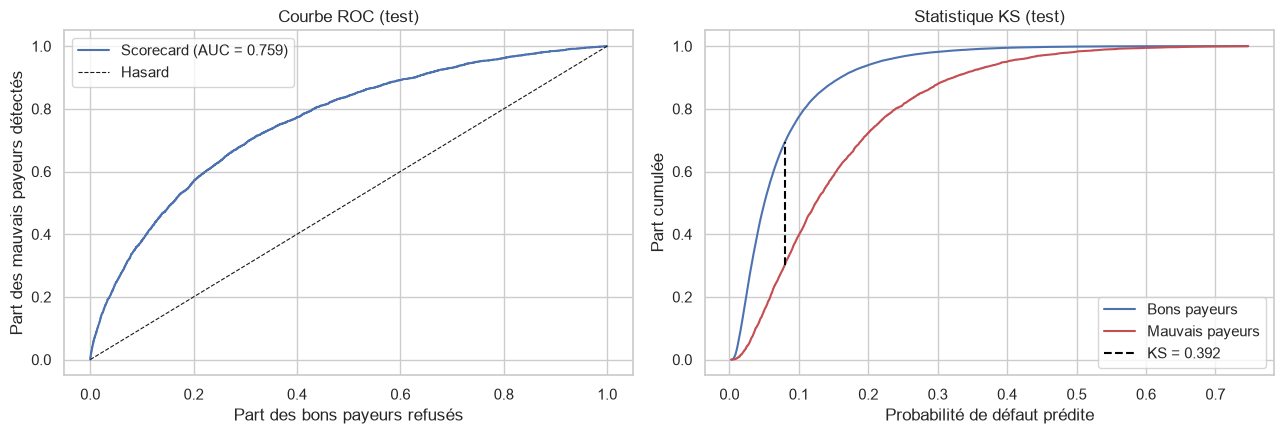

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

fpr, tpr, _ = roc_curve(y_test, pd_test)
m = evaluate(y_test, pd_test)
axes[0].plot(fpr, tpr, color="#4C72B0", label=f"Scorecard (AUC = {m['AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="Hasard")
axes[0].set_xlabel("Part des bons payeurs refusés"); axes[0].set_ylabel("Part des mauvais payeurs détectés")
axes[0].set_title("Courbe ROC (test)"); axes[0].legend()

thresholds = np.sort(pd_test)
cdf_bad = np.searchsorted(np.sort(pd_test[y_test == 1]), thresholds, side="right") / (y_test == 1).sum()
cdf_good = np.searchsorted(np.sort(pd_test[y_test == 0]), thresholds, side="right") / (y_test == 0).sum()
i = np.argmax(cdf_good - cdf_bad)
axes[1].plot(thresholds, cdf_good, color="#4C72B0", label="Bons payeurs")
axes[1].plot(thresholds, cdf_bad, color="#C44E52", label="Mauvais payeurs")
axes[1].vlines(thresholds[i], cdf_bad[i], cdf_good[i], color="black", ls="--", label=f"KS = {m['KS']:.3f}")
axes[1].set_xlabel("Probabilité de défaut prédite"); axes[1].set_ylabel("Part cumulée")
axes[1].set_title("Statistique KS (test)"); axes[1].legend()
plt.tight_layout(); plt.savefig(FIGURES / "03_roc_ks.png", dpi=120); plt.show()

### Le modèle classe-t-il bien les clients ?

On trie les demandes du test par risque prédit et on les coupe en 10 groupes égaux (déciles).
Si le modèle est bon, le taux de défaut réel doit **augmenter fortement** d'un décile à l'autre.

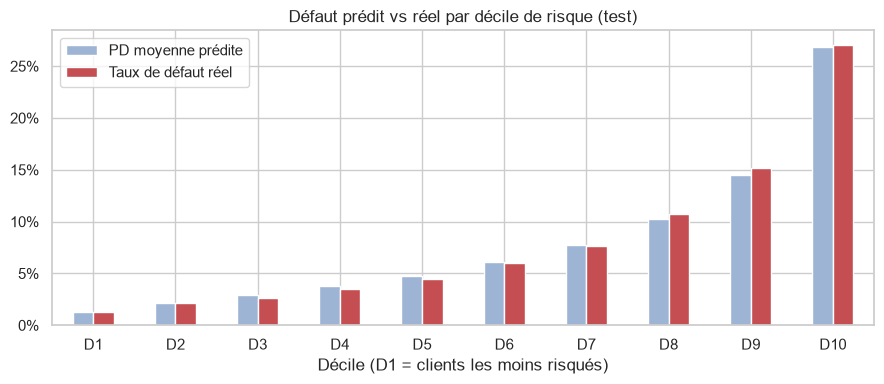

,PD moyenne prédite,Taux de défaut réel
D1,1.2%,1.3%
D2,2.1%,2.1%
D3,2.9%,2.6%
D4,3.8%,3.5%
D5,4.8%,4.5%
D6,6.1%,6.0%
D7,7.8%,7.7%
D8,10.2%,10.8%
D9,14.5%,15.2%
D10,26.8%,27.1%


In [9]:
deciles = pd.qcut(pd_test, 10, labels=[f"D{i}" for i in range(1, 11)])
by_decile = pd.DataFrame({"PD moyenne prédite": pd_test, "Taux de défaut réel": y_test.values}).groupby(deciles, observed=True).mean()

ax = by_decile.plot.bar(figsize=(9, 4), color=["#9DB4D4", "#C44E52"], rot=0)
ax.set_title("Défaut prédit vs réel par décile de risque (test)")
ax.set_xlabel("Décile (D1 = clients les moins risqués)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout(); plt.savefig(FIGURES / "03_deciles.png", dpi=120); plt.show()
by_decile.style.format("{:.1%}")

In [10]:
d = by_decile["Taux de défaut réel"]
print(f"Les 10 % les plus risqués font {d.iloc[-1]:.1%} de défauts, les 10 % les moins risqués {d.iloc[0]:.1%}")
print(f"soit {d.iloc[-1] / d.iloc[0]:.0f} fois plus.")

Les 10 % les plus risqués font 27.1% de défauts, les 10 % les moins risqués 1.3%
soit 21 fois plus.


## 6. Conclusions

- **18 variables** suffisent à atteindre un **Gini d'environ 0,52** sur des données jamais vues, sans surapprentissage.
- Le modèle **sépare nettement** les clients : le décile le plus risqué fait bien plus de défauts que le moins risqué.
- Les variables construites en SQL (ratios, historique de remboursement, refus passés, utilisation de carte) entrent dans le modèle.
- Le modèle est **explicable** : chaque variable a un sens métier et un effet dans le bon sens.

**Prochaine étape :** comparer avec **LightGBM**, un modèle plus puissant mais moins lisible, puis l'expliquer avec **SHAP**.